# Transformer Performance Tests

In [1]:
import sys
from pathlib import Path

ROOT = Path().resolve().parents[0]
sys.path.append(str(ROOT))
sys.path.append(str(ROOT / "src" / "data_generation"))
sys.path.append(str(ROOT / "src" / "models"))
sys.path.append(str(ROOT / "src" / "evaluation"))

In [2]:
# Required adding .vscode/settings.json to get highlighting to work!
from room_dataset import RoomDataset, collate_rooms, load_rooms_as_descriptions
from item_encoder import load_aligned_embeddings, load_item_catalog, DATA_PATH_SHORT, EMBEDDINGS_PATH_DF_SHORT
from transformer import FurnitureEmbeddingPredictor, TransformerEvaluator
from evaluator import LeaveOneOutEvaluator
from baseline_models import ItemContentBaseline, ItemItemCooccurrence, PopularityPrior

import torch, numpy as np, matplotlib.pyplot as plt, pandas as pd
from torch.utils.data import Dataset, DataLoader

In [7]:
# UNLABELED DATA =============================
train_dataset_unlabeled = RoomDataset("train", labeled=False, dataset = "df_short")
val_dataset_unlabeled = RoomDataset("val", labeled=False, dataset="df_short")
test_dataset_unlabeled = RoomDataset("test", labeled=False, dataset="df_short")

def make_dataloader_unlabeled(dataset) -> DataLoader:
    return DataLoader(dataset,
            batch_size=32,
            shuffle=True,
            collate_fn=collate_rooms,
        )

train_loader_unlabeled = make_dataloader_unlabeled(train_dataset_unlabeled)
val_loader_unlabeled = make_dataloader_unlabeled(val_dataset_unlabeled)
test_loader_unlabeled = make_dataloader_unlabeled(test_dataset_unlabeled)

In [4]:
print(train_dataset_unlabeled[0])

{'embeddings': tensor([[-0.0520,  0.0259, -0.0069,  ..., -0.0439, -0.0795,  0.0842],
        [ 0.0232,  0.0025, -0.0953,  ..., -0.0302, -0.0675,  0.0295],
        [ 0.0140, -0.0176, -0.1249,  ..., -0.0136, -0.0570,  0.0292],
        [-0.0394,  0.0486, -0.0433,  ..., -0.0588, -0.0252,  0.0483],
        [-0.0309,  0.0932, -0.0502,  ...,  0.0442,  0.0743,  0.0471],
        [-0.0309,  0.0932, -0.0502,  ...,  0.0442,  0.0743,  0.0471]]), 'item_ids': tensor([4260160, 9168473, 2739309, 3464833, 5822036, 5822036]), 'room_type': None}


In [5]:

# LABELED DATA =============================
train_dataset_labeled = RoomDataset("train", labeled=True)
val_dataset_labeled = RoomDataset("val", labeled=True)
test_dataset_labeled = RoomDataset("test", labeled=True)

def collate_rooms_labeled(batch):
    return collate_rooms(batch, labeled=True)

def make_dataloader_labeled(dataset) -> DataLoader:
    return DataLoader(dataset,
            batch_size=32,
            shuffle=True,
            collate_fn=collate_rooms_labeled,
        )

train_loader_labeled = make_dataloader_labeled(train_dataset_labeled)
val_loader_labeled = make_dataloader_labeled(val_dataset_labeled)
test_loader_labeled = make_dataloader_labeled(test_dataset_labeled)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loaded instance on device: mps with 5 candidate head(s)
Unlabeled model not found on disk, training...
Training with device: mps (loss: infonce, temp: 0.07, heads: 5)


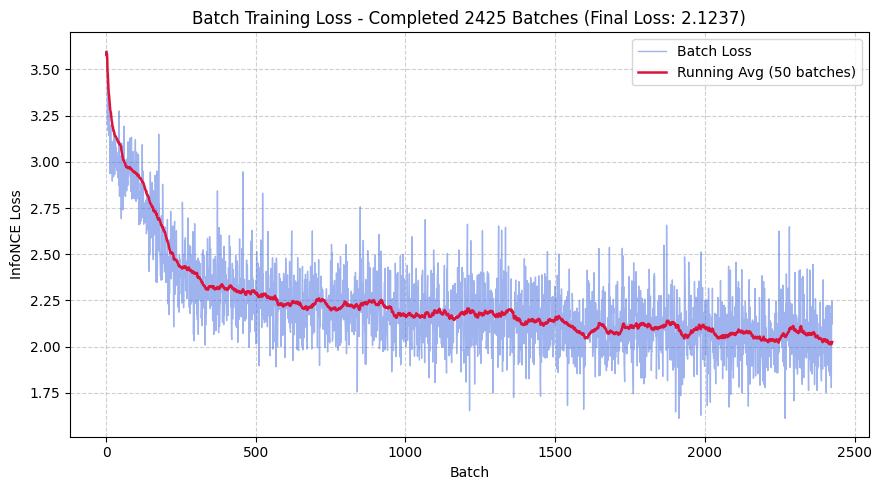

 20%|██        | 1/5 [00:20<01:22, 20.65s/it]

Average epoch training loss: 2.5521


 40%|████      | 2/5 [00:37<00:55, 18.63s/it]

Average epoch training loss: 2.2268


 60%|██████    | 3/5 [00:55<00:36, 18.32s/it]

Average epoch training loss: 2.1666


 80%|████████  | 4/5 [01:13<00:18, 18.02s/it]

Average epoch training loss: 2.1030


100%|██████████| 5/5 [01:30<00:00, 18.08s/it]

Average epoch training loss: 2.0638


In [8]:
model_unlabeled = FurnitureEmbeddingPredictor(nhead=4, num_candidates=5)

ul_model_filename = "df_short_transformer_unlabeled.pt"

try:
    model_unlabeled.load_state_dict(torch.load(str(ROOT/ "notebooks"/ ul_model_filename), weights_only=True))
except FileNotFoundError:
    print("Unlabeled model not found on disk, training...")
    model_unlabeled.fit(train_loader_unlabeled, labeled_data=False, epochs = 5, lr=1e-4, plot_every=10, loss_type="infonce")
    torch.save(model_unlabeled.state_dict(), str(ROOT/ "notebooks"/ ul_model_filename))

#l_model_filename = "mh_transfomer_labeled.pt"
#
#model_labeled = FurnitureEmbeddingPredictor(nhead=4, num_candidates=5)
#try:
#    model_labeled.load_state_dict(torch.load(str(ROOT/ "notebooks"/l_model_filename), weights_only=True))
#except FileNotFoundError:
#    print("Labeled model not found on disk, training...")
#    model_labeled.fit(train_loader_labeled, labeled_data=True, epochs = 5, lr=1e-4, plot_every=10, loss_type="infonce")
#    torch.save(model_labeled.state_dict(), str(ROOT/ "notebooks"/ l_model_filename))
#

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/774 [00:00<?, ?it/s]

100%|██████████| 1939/1939 [01:08<00:00, 28.50it/s]


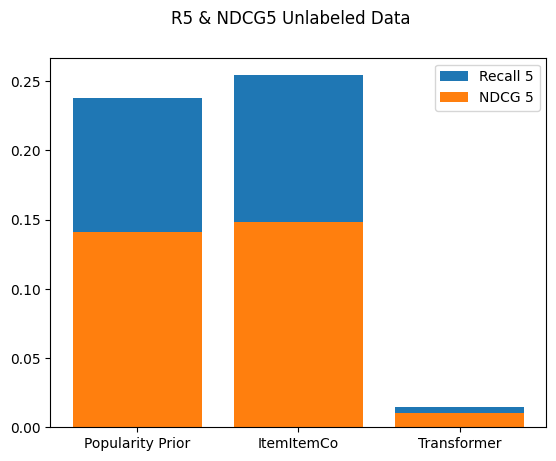

Pop-prior baseline r5: 0.2377514182568334, ndcg5: 0.1410265685544685
IIC baseline r5: 0.25425477050025785, ndcg5: 0.14794014291518642
Transformer r5: 0.01444043321299639, ndcg5: 0.010231549601438886


In [9]:
item_ids, item_descs = load_item_catalog(data_path=DATA_PATH_SHORT)
item_embeddings = load_aligned_embeddings(item_ids, embeddings_path=EMBEDDINGS_PATH_DF_SHORT)

#rooms_train_l = load_rooms_as_descriptions("train", labeled=True)
#rooms_val_l = load_rooms_as_descriptions("val", labeled=True)

rooms_train_ul = load_rooms_as_descriptions("train", labeled=False, dataset="df_short")
rooms_val_ul = load_rooms_as_descriptions("val", labeled=False, dataset="df_short")

# ItemContent baseline model currently does not work with labeled data!
#itemContent_model = ItemContentBaseline(item_ids, item_descs, return_descriptions=True)
#5_IC, ndcg5_IC = loo_evaluator.evaluate(itemContent_model, rooms_val, k=10)
#print(f"IC baseline r5: {r5_IC}, ndcg5: {ndcg5_IC}")

def get_and_display_metrics(rooms_train, rooms_val, transformer_model, labeled: bool = False):
    trans_evaluator_model = TransformerEvaluator(transformer_model, item_descriptions=item_descs, aggregation="confidence_weighted_max")
    itemItemCoccurance_model = ItemItemCooccurrence()
    itemItemCoccurance_model.fit(rooms_train)

    popPrior_model = PopularityPrior()
    popPrior_model.fit(rooms_train)

    loo_evaluator = LeaveOneOutEvaluator()

    r5_PP, ndcg5_PP = loo_evaluator.evaluate(popPrior_model, rooms_val, k=10, labeled=labeled)
    r5_IIC, ndcg5_IIC = loo_evaluator.evaluate(itemItemCoccurance_model, rooms_val, k=10, labeled=labeled)
    r5_T, ndcg5_T = loo_evaluator.evaluate(trans_evaluator_model, rooms_val, k=10, labeled=labeled)

    r5s = [r5_PP, r5_IIC, r5_T]
    ndcg5s = [ndcg5_PP, ndcg5_IIC, ndcg5_T]
    labels = ["Popularity Prior", "ItemItemCo", "Transformer"]
    fig, ax = plt.subplots()
    r5_bar = ax.bar(labels, r5s, label="Recall 5")
    ndcg5_bar = ax.bar(labels, ndcg5s, label="NDCG 5")
    if labeled: 
        plt.suptitle("R5 & NDCG5 Labeled Data")
    else:
        plt.suptitle("R5 & NDCG5 Unlabeled Data")
    plt.legend()
    plt.show()

    print(f"Pop-prior baseline r5: {r5_PP}, ndcg5: {ndcg5_PP}")
    print(f"IIC baseline r5: {r5_IIC}, ndcg5: {ndcg5_IIC}")
    print(f"Transformer r5: {r5_T}, ndcg5: {ndcg5_T}")

get_and_display_metrics(rooms_train_ul, rooms_val_ul, model_unlabeled, labeled=False)
#get_and_display_metrics(rooms_train_l, rooms_val_l, model_labeled, labeled=True)


In [17]:
# GENERATING ROOMS
import random

trans_evaluator_model = TransformerEvaluator(model_labeled, item_descriptions=item_descs, item_ids=item_ids, item_embeddings=item_embeddings, return_strings=True
                                                , aggregation="confidence_weighted_max")

def strip_items(items: list[str]):
    return [strip_item(item) for item in items]
def strip_item(item: str):
    stripped_left = item.split("Description: ")[-1]
    stripped_right = stripped_left.split(" Designer: ")[0]
    return stripped_right

#test_room = rooms[random.randrange(0, len(rooms))]
test_room = [rooms_val_l[0][0]]
for i in range(10):
    #print(f"Room:\n{strip_items(test_room)}\n")
    prediction = trans_evaluator_model.predict(test_room, k=3)
    test_room.append(prediction[0])
    #print(f"Predictions: \n {strip_items(prediction)}")
    
for item in test_room:
    print(item)

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

bedroom
Product series: STUVA / FRITIDS. Category: Beds. Description: Cot with drawers, 60x120 cm. Designer: Ebba Strandmark.
Product series: PLATSA. Category: Wardrobes. Description: Wardrobe, 95-120x42x181 cm. Designer: Ola Wihlborg/IKEA of Sweden.
Product series: ALEX. Category: Chests of drawers & drawer units. Description: Drawer unit with 9 drawers, 36x116 cm. Designer: Johanna Asshoff.
Product series: SVALNÄS. Category: Bookcases & shelving units. Description: Wall-mounted shelf combination, 66x25x176 cm. Designer: Jon Karlsson.
Product series: MICKE. Category: Chests of drawers & drawer units. Description: Drawer unit with drop-file storage, 35x75 cm. Designer: Henrik Preutz.
Product series: SVALNÄS. Category: Bookcases & shelving units. Description: Wall-mounted shelf combination, 193x25x176 cm. Designer: Jon Karlsson.
Product series: PLATSA. Category: Wardrobes. Description: Wardrobe, 195-220x57x241 cm. Designer: IKEA of Sweden/Ola Wihlborg.
Product series: BESTÅ. Category: B